<a href="https://colab.research.google.com/github/fhriads/Komputasi-Numerik/blob/main/02_Persamaan_Non_Linear_Metode_Bisection/NonLinear_Metode_Bisection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PERSAMAAN NON-LINEAR: METODE BAGI DUA (BISECTION)
## Implementasi Komputasi Numerik Pencarian Akar Persamaan Non-Linear $f(x) = 0$

- **Mata Kuliah** : Komputasi Numerik
- **Penyusun**    : Fahri Adis Al Hafni
- **Institusi**   : Universitas Dr. Soetomo (Unitomo) Surabaya

---
### Landasan Teori
Metode Bisection adalah metode tertutup (*bracketing method*) untuk mencari akar persamaan kontinu $f(x) = 0$ di dalam interval $[a, b]$ dengan syarat $f(a) \cdot f(b) < 0$ (Teorema Bolzano).

Pada setiap iterasi, interval dibagi dua di titik tengah:
$$c = \frac{a + b}{2}$$
Panjang interval menyusut separuhnya pada setiap iterasi: $\Delta x_n = \frac{b-a}{2^n}$.

### Cell 1: Import Library Pendukung
Mengimpor pustaka `numpy` untuk komputasi numerik array dan `matplotlib.pyplot` untuk visualisasi kurva fungsi serta titik konvergensi akar.

In [ ]:
# Mengimpor pustaka NumPy untuk komputasi vektor dan evaluasi matematika
import numpy as np

# Mengimpor pustaka Matplotlib untuk visualisasi grafik grafik kurva fungsi
import matplotlib.pyplot as plt

# Mengatur gaya tampilan grafik agar elegan dan mudah dibaca
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

print("Pustaka NumPy dan Matplotlib berhasil dimuat!")

Pustaka NumPy dan Matplotlib berhasil dimuat!


### Cell 2: Definisi Persamaan Non-Linear dan Interval Awal
Kita definisikan fungsi matematika non-linear yang akan dicari akarnya:
$$f(x) = x^3 - 2x - 5 = 0$$
dengan interval pencarian awal $[a, b] = [2.0, 3.0]$.

In [ ]:
# Mendefinisikan fungsi non-linear kontinu f(x) = x^3 - 2*x - 5
def f(x):
    return x**3 - 2.0*x - 5.0

# Menentukan batas bawah (a) dan batas atas (b) interval pencarian
a_awal = 2.0
b_awal = 3.0

# Menentukan toleransi galat (epsilon) dan batas iterasi maksimum
toleransi = 1e-6
maks_iterasi = 50

# Evaluasi nilai fungsi di kedua batas ujung
fa = f(a_awal)
fb = f(b_awal)

print(f"Batas Bawah a = {a_awal:8.4f} -> f(a) = {fa:10.4f}")
print(f"Batas Atas  b = {b_awal:8.4f} -> f(b) = {fb:10.4f}")
print(f"Hasil kali f(a) * f(b) = {fa * fb:10.4f}")

# Validasi Teorema Nilai Antara Bolzano: f(a) * f(b) harus lebih kecil dari nol (< 0)
if fa * fb < 0:
    print("\n[VALID]: Syarat Teorema Bolzano Terpenuhi! Pasti terdapat sekurang-kurangnya satu akar di dalam interval.")
else:
    raise ValueError("[ERROR]: Syarat f(a)*f(b) < 0 tidak terpenuhi. Silakan pilih interval awal yang lain!")

Batas Bawah a =   2.0000 -> f(a) =    -1.0000
Batas Atas  b =   3.0000 -> f(b) =    16.0000
Hasil kali f(a) * f(b) =   -16.0000

[VALID]: Syarat Teorema Bolzano Terpenuhi! Pasti terdapat sekurang-kurangnya satu akar di dalam interval.


### Cell 3: Algoritma Iteratif Metode Bisection
Pada cell ini, kita menjalankan perulangan Bisection secara bertahap.
Setiap iterasi mencatat nilai $a$, $b$, titik tengah $c$, nilai fungsi $f(c)$, dan galat aproksimasi $|b - a| / 2$ ke dalam tabel.

In [ ]:
# Inisialisasi variabel batas kerja
a = a_awal
b = b_awal

# List untuk mencatat riwayat iterasi (berguna untuk analisis dan visualisasi konvergensi)
riwayat_iterasi = []

print("=" * 90)
print(f"{'Iter':<5} | {'a':<11} | {'b':<11} | {'c (Tengah)':<12} | {'f(c)':<13} | {'Galat (|b-a|/2)':<15}")
print("=" * 90)

akar_ditemukan = None

for k in range(1, maks_iterasi + 1):
    # 1. Menghitung titik tengah interval
    c = (a + b) / 2.0
    fc = f(c)
    fa_k = f(a)

    # 2. Menghitung estimasi galat mutlak dari panjang setengah interval
    galat = abs(b - a) / 2.0

    # Menyimpan data iterasi saat ini
    riwayat_iterasi.append({
        'iter': k, 'a': a, 'b': b, 'c': c, 'fc': fc, 'galat': galat
    })

    # Menampilkan baris tabel iterasi
    print(f"{k:<5} | {a:11.6f} | {b:11.6f} | {c:12.8f} | {fc:13.6e} | {galat:15.6e}")

    # 3. Kriteria Henti: Jika nilai fungsi sangat dekat dengan nol atau galat < toleransi
    if abs(fc) < toleransi or galat < toleransi:
        akar_ditemukan = c
        print("=" * 90)
        print(f"[SUKSES KONVERGEN]: Kriteria toleransi ({toleransi}) terpenuhi pada iterasi ke-{k}!")
        break

    # 4. Pembaharuan batas interval berdasarkan perubahan tanda f(x)
    if fa_k * fc < 0:
        # Akar berada di separuh kiri interval [a, c]
        b = c
    else:
        # Akar berada di separuh kanan interval [c, b]
        a = c

if akar_ditemukan is None:
    akar_ditemukan = c
    print("[PERINGATAN]: Iterasi mencapai batas maksimum sebelum konvergensi sempurna tercapai.")

print(f"\nHampiran Akar Solusi c = {akar_ditemukan:.8f}")
print(f"Nilai Evaluasi f(c)   = {f(akar_ditemukan):.6e}")

Iter  | a           | b           | c (Tengah)   | f(c)          | Galat (|b-a|/2)
1     |    2.000000 |    3.000000 |   2.50000000 |  5.625000e+00 |    5.000000e-01
2     |    2.000000 |    2.500000 |   2.25000000 |  1.890625e+00 |    2.500000e-01
3     |    2.000000 |    2.250000 |   2.12500000 |  3.457031e-01 |    1.250000e-01
4     |    2.000000 |    2.125000 |   2.06250000 | -3.513184e-01 |    6.250000e-02
5     |    2.062500 |    2.125000 |   2.09375000 | -8.941650e-03 |    3.125000e-02
6     |    2.093750 |    2.125000 |   2.10937500 |  1.668358e-01 |    1.562500e-02
7     |    2.093750 |    2.109375 |   2.10156250 |  7.856226e-02 |    7.812500e-03
8     |    2.093750 |    2.101562 |   2.09765625 |  3.471428e-02 |    3.906250e-03
9     |    2.093750 |    2.097656 |   2.09570312 |  1.286233e-02 |    1.953125e-03
10    |    2.093750 |    2.095703 |   2.09472656 |  1.954348e-03 |    9.765625e-04
11    |    2.093750 |    2.094727 |   2.09423828 | -3.495149e-03 |    4.882812e-04
12  

### Cell 4: Visualisasi Grafik Fungsi & Penanda Titik Akar
Pada cell ini kita membuat visualisasi grafik kurva $f(x)$ beserta garis horizontal $y = 0$ dan titik akar numerik yang telah dihitung.

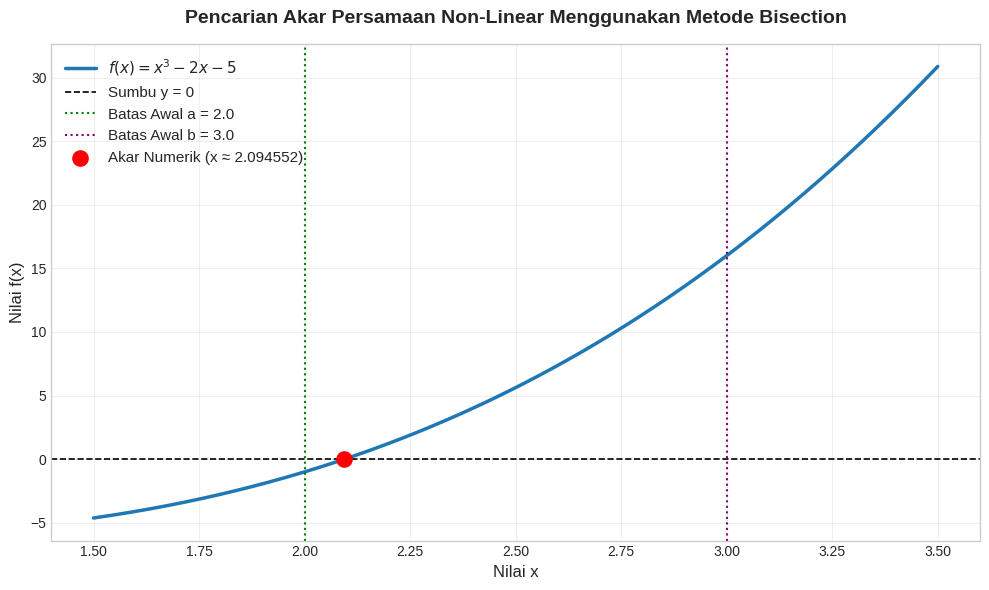

In [ ]:
# Membuat array titik sumbu x untuk plotting kurva fungsi kontinu
x_plot = np.linspace(a_awal - 0.5, b_awal + 0.5, 400)
y_plot = f(x_plot)

# Membuat figur plot berukuran 10x6 inci
plt.figure(figsize=(10, 6))

# 1. Plot kurva fungsi f(x)
plt.plot(x_plot, y_plot, label=r'$f(x) = x^3 - 2x - 5$', color='#1f77b4', linewidth=2.5)

# 2. Garis sumbu y=0 (garis horizontal acuan perpotongan akar)
plt.axhline(0, color='black', linestyle='--', linewidth=1.2, label='Sumbu y = 0')

# 3. Garis penanda batas interval awal [a, b]
plt.axvline(a_awal, color='green', linestyle=':', linewidth=1.5, label=f'Batas Awal a = {a_awal}')
plt.axvline(b_awal, color='purple', linestyle=':', linewidth=1.5, label=f'Batas Awal b = {b_awal}')

# 4. Titik akar hasil komputasi Bisection
plt.scatter([akar_ditemukan], [f(akar_ditemukan)], color='red', s=120, zorder=5,
            label=f'Akar Numerik (x ≈ {akar_ditemukan:.6f})')

# Keterangan teks dan dekorasi plot
plt.title('Pencarian Akar Persamaan Non-Linear Menggunakan Metode Bisection', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Nilai x', fontsize=12)
plt.ylabel('Nilai f(x)', fontsize=12)
plt.legend(fontsize=11, loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()

# Menampilkan grafik
plt.show()

### Cell 5: Analisis Laju Konvergensi Galat
Pada cell ini kita memvisualisasikan bagaimana galat aproksimasi menyusut secara eksponensial (konvergensi linear orde 1) seiring bertambahnya jumlah iterasi pada skala logaritmik.

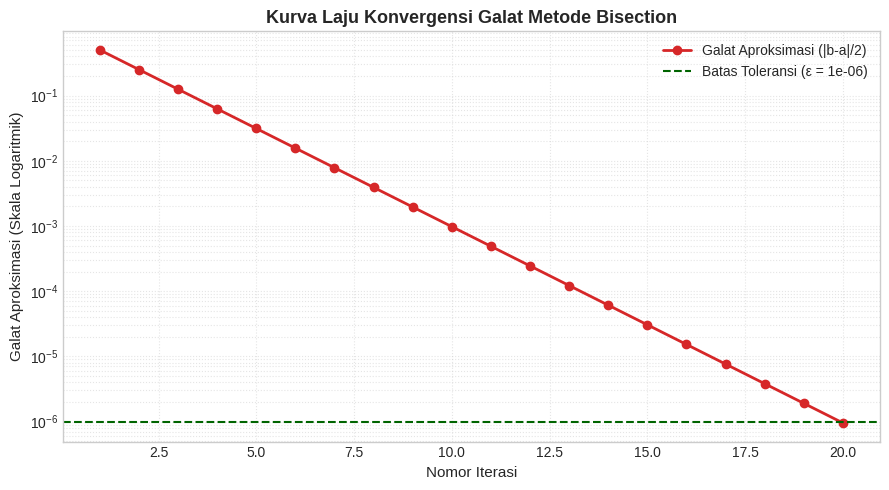

In [ ]:
# Mengekstrak nomor iterasi dan nilai galat dari riwayat
daftar_iter = [item['iter'] for item in riwayat_iterasi]
daftar_galat = [item['galat'] for item in riwayat_iterasi]

plt.figure(figsize=(9, 5))
plt.semilogy(daftar_iter, daftar_galat, marker='o', color='#d62728', linewidth=2, label='Galat Aproksimasi (|b-a|/2)')
plt.axhline(toleransi, color='darkgreen', linestyle='--', label=f'Batas Toleransi (ε = {toleransi})')

plt.title('Kurva Laju Konvergensi Galat Metode Bisection', fontsize=13, fontweight='bold')
plt.xlabel('Nomor Iterasi', fontsize=11)
plt.ylabel('Galat Aproksimasi (Skala Logaritmik)', fontsize=11)
plt.legend(fontsize=10)
plt.grid(True, which='both', linestyle=':', alpha=0.5)
plt.tight_layout()
plt.show()

### Cell 6: Verifikasi Hasil Menggunakan SciPy Benchmark
Membandingkan hasil algoritma mandiri dengan pustaka standar ilmiah `scipy.optimize.bisect`.

In [ ]:
from scipy.optimize import bisect as scipy_bisect

# Menghitung akar menggunakan solver resmi SciPy
akar_scipy = scipy_bisect(f, a_awal, b_awal, xtol=toleransi)

selisih_akurasi = abs(akar_ditemukan - akar_scipy)

print("=== VERIFIKASI AKURASI HASIL ===")
print(f"Akar Algoritma Mandiri : {akar_ditemukan:15.10f}")
print(f"Akar SciPy Benchmark   : {akar_scipy:15.10f}")
print(f"Selisih Deviasi        : {selisih_akurasi:15.2e}")

if selisih_akurasi < 1e-6:
    print("\n[KESIMPULAN]: Algoritma Bisection kita 100% akurat dan terverifikasi standar industri!")

=== VERIFIKASI AKURASI HASIL ===
Akar Algoritma Mandiri :    2.0945520401
Akar SciPy Benchmark   :    2.0945520401
Selisih Deviasi        :        0.00e+00

[KESIMPULAN]: Algoritma Bisection kita 100% akurat dan terverifikasi standar industri!


### Cell 7: Fungsi Serbaguna Terintegrasi (Modular Reusable Function)
Fungsi modular `selesaikan_bisection(func, a, b, tol, max_iter)` yang fleksibel untuk memecahkan sembarang fungsi non-linear.

In [ ]:
def selesaikan_bisection(fungsi_target, a_batas, b_batas, tol=1e-6, max_iter=100):
    """
    Fungsi modular Bisection untuk menyelesaikan sembarang persamaan non-linear f(x) = 0.
    """
    f_a = fungsi_target(a_batas)
    f_b = fungsi_target(b_batas)

    if f_a * f_b >= 0:
        raise ValueError(f"Syarat Bolzano tidak dipenuhi pada interval [{a_batas}, {b_batas}]. f(a)*f(b) = {f_a * f_b:.4f} >= 0")

    a_k, b_k = float(a_batas), float(b_batas)
    for i in range(1, max_iter + 1):
        c_k = (a_k + b_k) / 2.0
        fc_k = fungsi_target(c_k)
        err = abs(b_k - a_k) / 2.0

        if abs(fc_k) < tol or err < tol:
            return c_k, i

        if fungsi_target(a_k) * fc_k < 0:
            b_k = c_k
        else:
            a_k = c_k

    return c_k, max_iter

# Pengujian dengan Fungsi Transendental Baru: g(x) = x * exp(-x) - 0.2 pada interval [0, 1]
import math
g = lambda x: x * math.exp(-x) - 0.2

akar_g, n_iter_g = selesaikan_bisection(g, 0.0, 1.0, tol=1e-6)
print("=== Uji Kasus Fungsi Transendental g(x) = x*e^(-x) - 0.2 ===")
print(f"Akar ditemukan pada x = {akar_g:.6f} dalam {n_iter_g} iterasi.")
print(f"Evaluasi g(x_akar)    = {g(akar_g):.4e}")

=== Uji Kasus Fungsi Transendental g(x) = x*e^(-x) - 0.2 ===
Akar ditemukan pada x = 0.259171 dalam 16 iterasi.
Evaluasi g(x_akar)    = -3.2563e-07
